In [1]:
#Libraries
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openpyxl
from IPython.display import Markdown
import tabulate

In [2]:
ozone = pd.read_excel(r"C:\Users\darre\OneDrive\Documents\STATS 780\Assignment 2\Ozone.xlsx", sheet_name='Sheet1')
particulate = pd.read_excel(r"C:\Users\darre\OneDrive\Documents\STATS 780\Assignment 2\Particulate.xlsx", sheet_name='Sheet1')

In [3]:
hour_columns = [f"H{i:02d}" for i in range(1, 25)]

particulate = particulate.melt(
    id_vars=["Station ID", "Pollutant", "Date"],
    value_vars=hour_columns,
    var_name="Hour",
    value_name="Concentration"
)

particulate["Date"] = (
    pd.to_datetime(particulate["Date"])
    + pd.to_timedelta(
        particulate["Hour"].str[1:].astype(int) - 1,
        unit="h"
    )
)

particulate = (
    particulate
    .drop(columns="Hour")
    .sort_values(["Station ID", "Pollutant", "Date"])
    .reset_index(drop=True)
)



In [4]:
ozone = ozone.melt(
    id_vars=["Station ID", "Pollutant", "Date"],
    value_vars=hour_columns,
    var_name="Hour",
    value_name="Concentration"
)

ozone["Date"] = (
    pd.to_datetime(ozone["Date"])
    + pd.to_timedelta(
        ozone["Hour"].str[1:].astype(int) - 1,
        unit="h"
    )
)

ozone = (
    ozone
    .drop(columns="Hour")
    .sort_values(["Station ID", "Pollutant", "Date"])
    .reset_index(drop=True)
)

In [5]:
particulate

,Station ID,Pollutant,Date,Concentration
0,29118,Fine Particulate Matter,2025-01-01 00:00:00,7
1,29118,Fine Particulate Matter,2025-01-01 01:00:00,2
2,29118,Fine Particulate Matter,2025-01-01 02:00:00,1
3,29118,Fine Particulate Matter,2025-01-01 03:00:00,1
4,29118,Fine Particulate Matter,2025-01-01 04:00:00,0
...,...,...,...,...
8755,29118,Fine Particulate Matter,2025-12-31 19:00:00,3
8756,29118,Fine Particulate Matter,2025-12-31 20:00:00,2
8757,29118,Fine Particulate Matter,2025-12-31 21:00:00,1
8758,29118,Fine Particulate Matter,2025-12-31 22:00:00,1


In [6]:
# Check duplicate observations

duplicate_observations_p = particulate[
    particulate.duplicated(subset=["Station ID", "Date"], keep=False)
].sort_values(["Station ID", "Date"])

print(duplicate_observations_p.head())
print(f"Duplicate observation rows (particulate): {len(duplicate_observations_p)}")


      Station ID                Pollutant                Date  Concentration
1032       29118  Fine Particulate Matter 2025-02-13 00:00:00             11
1033       29118  Fine Particulate Matter 2025-02-13 00:00:00           -999
1034       29118  Fine Particulate Matter 2025-02-13 01:00:00              6
1035       29118  Fine Particulate Matter 2025-02-13 01:00:00           -999
1036       29118  Fine Particulate Matter 2025-02-13 02:00:00              7
Duplicate observation rows (particulate): 48


In [7]:
duplicate_observations_o = ozone[
    ozone.duplicated(subset=["Station ID", "Date"], keep=False)
].sort_values(["Station ID", "Date"])

print(duplicate_observations_o.head())
print(f"Duplicate observation rows (ozone): {len(duplicate_observations_o)}")

      Station ID Pollutant                Date  Concentration
1032       29118     Ozone 2025-02-13 00:00:00             21
1033       29118     Ozone 2025-02-13 00:00:00           -999
1034       29118     Ozone 2025-02-13 01:00:00             20
1035       29118     Ozone 2025-02-13 01:00:00           -999
1036       29118     Ozone 2025-02-13 02:00:00             16
Duplicate observation rows (ozone): 48


In [8]:
# For duplicate dates and times, take either the first 
# legitimate measurement, or the measurement that is not invalid

# Treat these sentinel values as errors. Add any other error codes used in your data.
error_values = {-999, 999, 9999}

particulate["Concentration"] = pd.to_numeric(
    particulate["Concentration"], errors="coerce"
)

valid = (
    particulate["Concentration"].notna()
    & ~particulate["Concentration"].isin(error_values)
)

particulate = (
    particulate.assign(_valid=valid, _order=range(len(particulate)))
    .sort_values(["_valid", "_order"], ascending=[False, True], kind="stable")
    .drop_duplicates(subset=["Station ID", "Date"], keep="first")
    .sort_values("_order", kind="stable")
    .drop(columns=["_valid", "_order"])
    .reset_index(drop=True)
)

In [9]:
ozone = (
    ozone.assign(_valid=valid, _order=range(len(ozone)))
    .sort_values(["_valid", "_order"], ascending=[False, True], kind="stable")
    .drop_duplicates(subset=["Station ID", "Date"], keep="first")
    .sort_values("_order", kind="stable")
    .drop(columns=["_valid", "_order"])
    .reset_index(drop=True)
)

In [10]:
# ozone_clean.to_excel("ozone_transformed.xlsx", index=False)
# particulate_clean.to_excel("pm2.5_transformed.xlsx", index=False)

In [11]:
ozone = (
    ozone
    .rename(columns={"Concentration": "ozone"})
    .drop(columns = 'Pollutant')
)

In [12]:
ozone

,Station ID,Date,ozone
0,29118,2025-01-01 00:00:00,19
1,29118,2025-01-01 01:00:00,23
2,29118,2025-01-01 02:00:00,23
3,29118,2025-01-01 03:00:00,23
4,29118,2025-01-01 04:00:00,24
...,...,...,...
8731,29118,2025-12-31 19:00:00,31
8732,29118,2025-12-31 20:00:00,34
8733,29118,2025-12-31 21:00:00,38
8734,29118,2025-12-31 22:00:00,35


In [13]:
particulate = (
    particulate
    .rename(columns={"Concentration": "PM2.5"})
    .drop(columns = 'Pollutant')
)

In [14]:
merge = pd.merge(ozone, particulate, on='Date', how='inner')
merge

,Station ID_x,Date,ozone,Station ID_y,PM2.5
0,29118,2025-01-01 00:00:00,19,29118,7
1,29118,2025-01-01 01:00:00,23,29118,2
2,29118,2025-01-01 02:00:00,23,29118,1
3,29118,2025-01-01 03:00:00,23,29118,1
4,29118,2025-01-01 04:00:00,24,29118,0
...,...,...,...,...,...
8731,29118,2025-12-31 19:00:00,31,29118,3
8732,29118,2025-12-31 20:00:00,34,29118,2
8733,29118,2025-12-31 21:00:00,38,29118,1
8734,29118,2025-12-31 22:00:00,35,29118,1


In [15]:
merge = (
    merge
    .rename(columns={"Station ID_x": "Station ID"})
    .drop(columns= 'Station ID_y')
)

In [16]:
merge

,Station ID,Date,ozone,PM2.5
0,29118,2025-01-01 00:00:00,19,7
1,29118,2025-01-01 01:00:00,23,2
2,29118,2025-01-01 02:00:00,23,1
3,29118,2025-01-01 03:00:00,23,1
4,29118,2025-01-01 04:00:00,24,0
...,...,...,...,...
8731,29118,2025-12-31 19:00:00,31,3
8732,29118,2025-12-31 20:00:00,34,2
8733,29118,2025-12-31 21:00:00,38,1
8734,29118,2025-12-31 22:00:00,35,1


In [17]:
# merge.to_excel("output2.xlsx", index=False)

In [18]:
#convert invalid values to NaNs so they don't become outliers

merge["ozone"] = merge["ozone"].replace([9999,-999,999], np.nan)
merge["PM2.5"] = merge["PM2.5"].replace([9999,-999,999], np.nan)

In [19]:
# the number of NaN's matches the number of invalid numbers

print(merge[["ozone", "PM2.5"]].isna().sum())

ozone    115
PM2.5     64
dtype: int64


In [20]:
merge.loc[
    merge["Date"].dt.date == pd.Timestamp("2025-01-13").date()]

,Station ID,Date,ozone,PM2.5
288,29118,2025-01-13 00:00:00,32.0,11.0
289,29118,2025-01-13 01:00:00,32.0,11.0
290,29118,2025-01-13 02:00:00,31.0,11.0
291,29118,2025-01-13 03:00:00,NaN,11.0
292,29118,2025-01-13 04:00:00,31.0,13.0
293,29118,2025-01-13 05:00:00,31.0,8.0
294,29118,2025-01-13 06:00:00,26.0,7.0
295,29118,2025-01-13 07:00:00,23.0,9.0
296,29118,2025-01-13 08:00:00,22.0,8.0
297,29118,2025-01-13 09:00:00,21.0,10.0


In [21]:
# Used linear interpolation to fill in missing values

merge["Date"] = pd.to_datetime(merge["Date"], errors="coerce")
merge = merge.sort_values(["Station ID", "Date"])

# Interpolate measurement columns, not the numeric station identifier.
value_cols = [
    col for col in merge.select_dtypes(include="number").columns
    if col != "Station ID"
]

# Interpolate using actual time intervals, independently for each station.
merge[value_cols] = (
    merge.set_index("Date")
    .groupby("Station ID")[value_cols]
    .transform(
        lambda values: values.interpolate(
            method="time",
            limit_area="inside",
        )
    )
    .to_numpy()
)

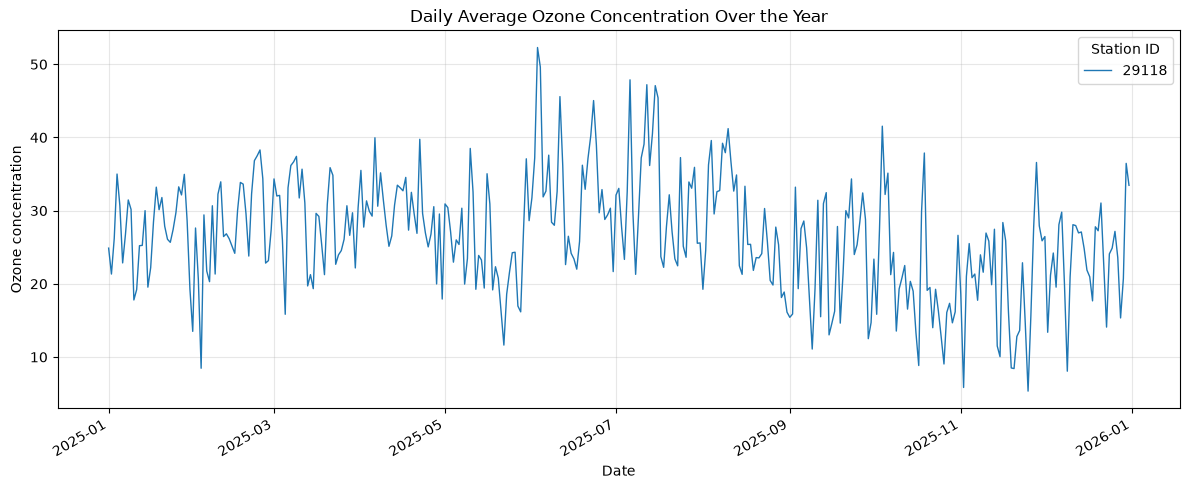

In [22]:
#takes hourly ozone measurements, calculates the average concentration 
#for each day, and plots those daily averages over the year.

ozone_col = "ozone"  # Replace with the exact ozone column name from merge.columns

df = merge.copy()
df = df.dropna(subset=["Date", ozone_col])
df["_day"] = df["Date"].dt.floor("D")

if "Station ID" in df.columns:
    daily = df.groupby(["_day", "Station ID"])[ozone_col].mean().unstack()
    ax = daily.plot(figsize=(12, 5), linewidth=1)
    ax.legend(title="Station ID")
else:
    daily = df.groupby("_day")[ozone_col].mean()
    ax = daily.plot(figsize=(12, 5), linewidth=1)

ax.set(
    title="Daily Average Ozone Concentration Over the Year",
    xlabel="Date",
    ylabel="Ozone concentration",
)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

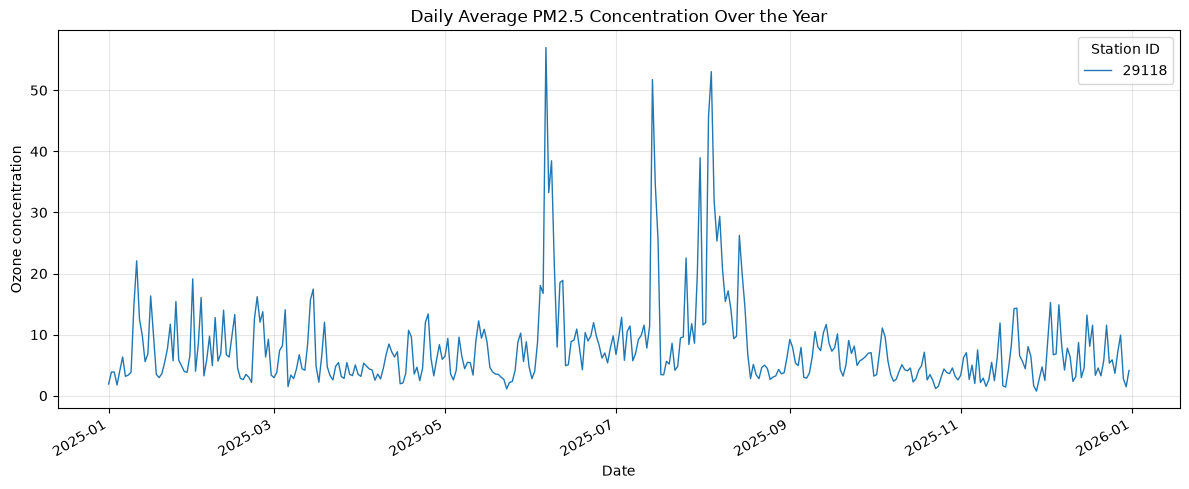

In [23]:
#takes hourly PM2.5 measurements, calculates the average concentration 
#for each day, and plots those daily averages over the year.

pm_col = "PM2.5"  # Replace with the exact ozone column name from merge.columns

df = merge.copy()
df = df.dropna(subset=["Date", pm_col])
df["_day"] = df["Date"].dt.floor("D")

if "Station ID" in df.columns:
    daily = df.groupby(["_day", "Station ID"])[pm_col].mean().unstack()
    ax = daily.plot(figsize=(12, 5), linewidth=1)
    ax.legend(title="Station ID")
else:
    daily = df.groupby("_day")[pm_col].mean()
    ax = daily.plot(figsize=(12, 5), linewidth=1)

ax.set(
    title="Daily Average PM2.5 Concentration Over the Year",
    xlabel="Date",
    ylabel="Ozone concentration",
)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
# Merge the data on date; change the key or column names to match your data.

merge["Date"] = pd.to_datetime(merge["Date"])
merge = merge[["Date", "ozone"]].dropna().sort_values("Date")

# FFT requires regular sampling. This calculates frequency in cycles per day.
intervals = merge["Date"].diff().dropna().dt.total_seconds() / 86400
if not np.allclose(intervals, intervals.iloc[0]):
    raise ValueError("Dates must be evenly spaced for this FFT calculation.")

ozone = merge["ozone"].to_numpy(dtype=float)
ozone = ozone - ozone.mean()  # Remove the average level

frequencies = np.fft.rfftfreq(len(ozone), d=intervals.iloc[0])
power = np.abs(np.fft.rfft(ozone)) ** 2

# Ignore zero frequency (the average) and find the strongest remaining frequency.
nonzero = frequencies > 0
dominant_idx = np.argmax(power[nonzero])
dominant_frequency = frequencies[nonzero][dominant_idx]

print(f"Dominant frequency: {dominant_frequency:.6g} cycles/day")
print(f"Corresponding period: {1 / dominant_frequency:.2f} days")

ValueError: Dates must be evenly spaced for this FFT calculation.